**Module End  Assignment: Python For Data Analysis**

**Project Title: Social Media Engagement Analytics Using Python**

❖ **Task 1 — Data Import & Setup**

* **Import CSV using Pandas**

In [ ]:
from google.colab import files
upload=files.upload()

Saving social_media_engagement_5000.csv to social_media_engagement_5000.csv


In [ ]:
import pandas as pd
df=pd.read_csv("social_media_engagement_5000.csv")
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


**Explanation**
* import pandas as pd --> Loads pandas library to handle data.
* pd.read_csv() --> Reads the CSV file into a table called df.
* df.head()--> shows first 5 rows to check data.

* **Check/convert data types**



In [ ]:
df.shape

(5000, 19)

**Explanation**
* df.shape()--> indicates 5000 rows and 19 columns.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


**Explanation**
* df.info()--> shows how many values are missing and what type each column is.

* **Convert date columns to datetime**

In [ ]:
df['posted_at']=pd.to_datetime(df['posted_at'], dayfirst=True, errors='coerce')

In [ ]:
print(df['posted_at'].dtype)

datetime64[ns]


**Explanation**
* pd.to_datetime()--> converts that text into real date format.
* dayfirst=True--> to convey python that date is DD/MM/YYYY format.
* errors='coerce'--> If any wrong date is there,make it blank(NaT) instead of error.

* **Use NumPy arrays for basic array operations**

In [ ]:
df['likes']=pd.to_numeric(df['likes'],errors='coerce')
df['comments']=pd.to_numeric(df['comments'],errors='coerce')
df['shares']=pd.to_numeric(df['shares'],errors='coerce')
df['engagement_rate']=pd.to_numeric(df['engagement_rate'],errors='coerce')

* pd.to_numeric(..Changed data type of likes,comments,shares,engagement_rate before array operations.

In [ ]:
df['likes']=df['likes'].fillna(df['likes'].median())
df['shares']=df['shares'].fillna(df['shares'].median())
df['comments']=df['comments'].fillna(df['comments'].median())
df['engagement_rate']=df['engagement_rate'].fillna(df['engagement_rate'].median())

* fillna()--> Fill blank cells.
* median()--> The middle value of the column.
* So if likes has blanks, it will be filled with the median likes values.
* Did same for shares,comments, engagement_rate.

In [ ]:
import numpy as np

* import numpy as np--> load numpy library.

In [ ]:
likes = np.array(df['likes'])
comments = np.array(df['comments'])
shares = np.array(df['shares'])
engagement_rate = np.array(df['engagement_rate'])

* np.array()--> coverts the pandas column into a numpy array and this makes mathematical calculations faster.

In [ ]:
print("Total Likes:",np.sum(likes))
print("Mean Likes:",np.mean(likes))
print("Max Comments:",np.max(comments))
print("Min Shares:",np.min(shares))
print("Std Engagement_rate:",np.std(engagement_rate))

Total Likes: 50534987.0
Mean Likes: 10106.9974
Max Comments: 2999.0
Min Shares: 0.0
Std Engagement_rate: 5.317497393146468


* np.sum(likes)--> Total likes, sums all likes in the dataset. Total 5 Crore+ likes from 5000 posts.
* np.mean(),Average likes per post.
* np.max(), Max comments which is 2999.
* np.min(),min shares:0.0
* np.std(), Standard Deviation shows how much engagement_rate varies.

❖ **Task 2 — Data Cleaning**

* **Cleaning Missing Data**
* Detect missing values (isnull(), isna())
* Handle using: dropna(), fillna(), median/mode, forward/backward-fill

In [ ]:
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


In [ ]:
df['age']=pd.to_numeric(df['age'],errors='coerce')
df['age']=df['age'].fillna(df['age'].median())
df['gender']=df['gender'].fillna('Unknown')
df['sentiment']=df['sentiment'].fillna(df['sentiment'].mode()[0])

**Explanation**
* df.isnull().sum()--> shows the missing values with counts.
* age,gender,sentiment columns shows 150 missings each.
* To handle the missing values in age fillna() with median is applied.
* In 'gender' filled with 'Unknown'.
* In 'sentiment' filled with most frequent values, mode()[0].

In [ ]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


* df.isnull().sum()--> shows 0, there is no more missing values.

**Duplicate Handling**

* **Identify & remove duplicates**

In [ ]:
df.duplicated().sum()

np.int64(0)

**Explanation**
* df.duplicated().sum()- will count the total number of duplicates if any found in our dataset.
* Output shows (0)- No duplicates found here.

* **Data Formatting**

* **Fix incorrect data types**

In [ ]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


In [ ]:
df['age']=df['age'].astype('int64')
df['likes']=df['likes'].astype('int64')
df['comments']=df['comments'].astype('int64')
df['shares']=df['shares'].astype('int64')

* Here the columns age,likes,comments and shares are showing wrong data types.
* .astype('int64') -->To covert it into int64.

In [ ]:
df.dtypes

,0
user_id,int64
age,int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,int64
comments,int64
shares,int64


* df.dtypes --> shows the data format was now corrected.

* **Standardize categories (e.g., gender labels)**

In [ ]:
for col in ['gender', 'post_type', 'post_category', 'device_type', 'sentiment', 'country']:
  print(df[col].value_counts(dropna=False))

gender
Male       1699
Other      1581
Female     1570
Unknown     150
Name: count, dtype: int64
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64


In [ ]:
df['post_type']=df['post_type'].astype(str).str.strip().str.title()
df['post_category']=df['post_category'].astype(str).str.strip().str.title()
df['device_type']=df['device_type'].astype(str).str.strip().str.title()
df['sentiment']=df['sentiment'].astype(str).str.strip().str.title()

**Explanation**
* .value_counts() to check the frequency. This shows how many times each type occurs.
* str.strip()--> Removes extra space.
* str.title()--> Makes first letter capital.

In [ ]:
for col in ['gender', 'post_type', 'post_category', 'device_type', 'sentiment', 'country']:
  print(df[col].value_counts(dropna=False))

gender
Male       1699
Other      1581
Female     1570
Unknown     150
Name: count, dtype: int64
post_type
Reel     1283
Image    1247
Text     1245
Video    1225
Name: count, dtype: int64
post_category
Fitness      675
Tech         665
Music        635
Education    631
Lifestyle    607
Travel       600
Fashion      594
Food         593
Name: count, dtype: int64
device_type
Mobile     1684
Tablet     1658
Desktop    1658
Name: count, dtype: int64
sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64


* print(df[col].value_counts(dropna=False))--> shows the standardized form.

* **Correct unrealistic values in likes, comments, shares**

In [ ]:
print(df[['likes','comments','shares']].describe())

              likes     comments     shares
count   5000.000000  5000.000000  5000.0000
mean   10106.982400  1502.039800  1002.9106
std     5702.293022   856.393312   570.8552
min       10.000000     0.000000     0.0000
25%     5235.000000   792.000000   511.0000
50%    10105.000000  1497.000000  1012.0000
75%    14959.000000  2235.250000  1483.0000
max    19998.000000  2999.000000  1999.0000


**Explanation**
* Unrealistic values means negative values.
* '.describe()'- will describes the statistical structure, from this we can easily findout the max and min value present in each likes,shares and comments.
* Output clearly shows there is no negative values.

* **Feature Cleaning**

* **Clean sentiment labels**

In [ ]:
print(df['sentiment'].value_counts(dropna=False))

sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64


**Explanation**
* In previous part in sentiment labels are cleaned.
* print(df['sentiment'].value_counts(dropna=False))- just to verify the label is already corrected.

* **Extract hashtag count**

In [ ]:
df['hashtag_count']=df['hashtags'].astype(str).str.count('#')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

**Explanation**
* df['hashtag_count']=df['hashtags'].astype(str).str.count('#')--> This creates a new column called hashtag_count and str.count('#') = Counts how many # symbols are there in each row.
* df.info()--> shows summary of the dataset and we can easily note that there is no missing values and type error. This confirms dataset is now clean and ready for analysis.

❖ **Task 3 — Data Exploration using Pandas**

* **View dataset structure using head(), tail(), shape, and columns.**

In [ ]:
print("Head:")
print(df.head())

Head:
   user_id  age  gender country  post_id post_type post_category  likes  \
0    25795   43  Female  Brazil   496713     Image       Fitness   7011   
1    10860   33    Male  Brazil   157326      Reel          Food  11750   
2    86820   32  Female      UK   109864      Text          Food   4862   
3    64886   51   Other  France   848877      Text       Fitness   5350   
4    16265   34   Other      UK   449706     Image       Fitness  12682   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0       354    1157            5726             44650 2022-12-17   
1      2606    1807            5947             80216 2023-06-02   
2       344     955            6946             44858 2023-05-07   
3      1083    1049             229             70455 2023-02-12   
4      2735    1300            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      Mobile  Negative  #

In [ ]:
print("Tail:")
print(df.tail())

Tail:
      user_id  age  gender    country  post_id post_type post_category  likes  \
4995    59500   44    Male  Australia   441541     Video     Education  16210   
4996    22100   38   Other        UAE   677076      Reel     Education  16924   
4997    67021   63  Female        USA   273595      Text        Travel  13487   
4998    29800   13  Female    Germany   785644     Video       Fitness  16894   
4999    73400   54   Other      Japan   712252      Text        Travel  14830   

      comments  shares  watch_time_sec  impression_count  posted_at  \
4995      2013    1837            6190             42977 2022-06-25   
4996      2734    1583            7764             34196 2022-11-18   
4997      1497     167            7466             23680 2023-04-06   
4998      1289    1713            4991             89013 2022-05-16   
4999       503    1798            3743             14234 2023-03-04   

      follower_count  is_verified device_type sentiment  \
4995          646147 

In [ ]:
print("Shape:")
print(df.shape)

Shape:
(5000, 20)


In [ ]:
print("Columns:")
print(df.columns.tolist())

Columns:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


**Explanation**
* df.head()--> shows the first 5 rows of the dataset.
* df.tail()--> shows the last 5 rows of the dataset.
* df.shape--> shows the total count of rows and columns.
* df.columns.tolist()--> shows list of all column names in the dataset.

* **Check data types and info with info() and dtypes.**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [ ]:
df.dtypes

,0
user_id,int64
age,int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,int64
comments,int64
shares,int64


* df.info() --> shows the summary of dataset and confirms there is no missing values.
* df.dtypes--> shows the data type of each column.

* **Generate summary statistics using describe().**

In [ ]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.982400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293022,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


* **Analyze categorical distributions using value_counts(), unique(), and
nunique().**

In [ ]:
cat_cols = ['gender', 'country', 'post_type', 'post_category', 'device_type','sentiment','is_verified']

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())
    print(f"Unique: {df[col].unique()}")
    print(f"Nunique: {df[col].nunique()}")


--- gender ---
gender
Male       1699
Other      1581
Female     1570
Unknown     150
Name: count, dtype: int64
Unique: ['Female' 'Male' 'Other' 'Unknown']
Nunique: 4

--- country ---
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64
Unique: ['Brazil' 'UK' 'France' 'Canada' 'Japan' 'Australia' 'India' 'UAE'
 'Germany' 'USA']
Nunique: 10

--- post_type ---
post_type
Reel     1283
Image    1247
Text     1245
Video    1225
Name: count, dtype: int64
Unique: ['Image' 'Reel' 'Text' 'Video']
Nunique: 4

--- post_category ---
post_category
Fitness      675
Tech         665
Music        635
Education    631
Lifestyle    607
Travel       600
Fashion      594
Food         593
Name: count, dtype: int64
Unique: ['Fitness' 'Food' 'Tech' 'Travel' 'Fashion' 'Lifestyle' 'Education'
 'Music']
Nunique: 8

--- device_type ---
device_type
Mobile     1684

**Explanation**
* cat_cols = [...] - made a list of all category columns.
* for col in cat_cols: - Loop will run for each column one by one.
* value_counts() -> Counts how many times each value appears.
* unique() -> Shows what are the different values.
* nunique() -> Shows how many different values.

* **Create a correlation matrix for numeric fields.**

In [ ]:
numeric_df = df[['age','likes','shares','comments','watch_time_sec','impression_count','follower_count','hashtag_count','engagement_rate']]
corr_matrix =numeric_df.corr()
print(corr_matrix)

                       age     likes    shares  comments  watch_time_sec  \
age               1.000000 -0.036323  0.013871 -0.007284        0.005542   
likes            -0.036323  1.000000  0.004712 -0.018421        0.008710   
shares            0.013871  0.004712  1.000000  0.006142        0.014658   
comments         -0.007284 -0.018421  0.006142  1.000000       -0.016351   
watch_time_sec    0.005542  0.008710  0.014658 -0.016351        1.000000   
impression_count  0.013322  0.007952 -0.005204 -0.009395       -0.004335   
follower_count   -0.024894 -0.022982 -0.010783 -0.011733        0.002761   
hashtag_count     0.007173 -0.002190  0.013379 -0.015230       -0.023301   
engagement_rate   0.008039  0.093521  0.021724  0.000051       -0.001148   

                  impression_count  follower_count  hashtag_count  \
age                       0.013322       -0.024894       0.007173   
likes                     0.007952       -0.022982      -0.002190   
shares                   -0.0052

**Explanation**
* numeric_df = df[[...]] - selected only number columns from the dataset. Correlation works only on numbers.
* corr_matrix = numeric_df.corr() - .corr() calculates correlation.
* print(corr_matrix) - Shows the table.

* **Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).**

In [ ]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493,1
2,86820,32,Female,UK,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,UK,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372,1


In [ ]:
df.groupby('post_type')['likes'].mean().round(2).reset_index()

,post_type,likes
0,Image,10104.85
1,Reel,10037.78
2,Text,10100.13
3,Video,10188.59


In [ ]:
df.groupby('device_type')['watch_time_sec'].mean().round(2).reset_index()

,device_type,watch_time_sec
0,Desktop,3974.79
1,Mobile,4087.83
2,Tablet,3979.74


In [ ]:
df.groupby('post_type')['shares'].mean().round(2).reset_index()

,post_type,shares
0,Image,1019.29
1,Reel,982.04
2,Text,1013.99
3,Video,996.83


In [ ]:
df.groupby('post_category')['engagement_rate'].mean().sort_values(ascending=False).round(2).reset_index()

,post_category,engagement_rate
0,Food,1.36
1,Tech,1.16
2,Lifestyle,1.09
3,Music,0.89
4,Fitness,0.87
5,Education,0.84
6,Fashion,0.81
7,Travel,0.70


In [ ]:
df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False).round(2).reset_index()

,country,engagement_rate
0,Brazil,1.54
1,Australia,1.32
2,France,1.15
3,UAE,1.11
4,Canada,0.92
5,UK,0.85
6,Japan,0.77
7,Germany,0.76
8,India,0.66
9,USA,0.58


In [ ]:
df.groupby('is_verified')['engagement_rate'].mean().sort_values(ascending=False).round(2).reset_index()

,is_verified,engagement_rate
0,True,1.05
1,False,0.95


In [ ]:
df.groupby('country')['impression_count'].mean().sort_values(ascending=False).round(2).reset_index()

,country,impression_count
0,India,10.61
1,USA,10.58
2,UK,10.57
3,France,10.53
4,Brazil,10.51
5,Germany,10.51
6,Canada,10.49
7,Japan,10.49
8,UAE,10.46
9,Australia,10.44


In [ ]:
sentiment_perf = df.groupby('sentiment')[['likes','shares','watch_time_sec','impression_count']].mean().sort_values(by ='impression_count',ascending=False).round(2).reset_index()
print(sentiment_perf)

  sentiment     likes   shares  watch_time_sec  impression_count
0  Positive  10180.05  1005.09         3988.65             10.54
1  Negative  10208.08  1007.31         4054.64             10.51
2   Neutral   9923.18   996.57         4031.82             10.50


**Explanation**
* df.head() -> Shows first 5 rows to check data.
* df.groupby('post_type')['likes'].mean().round(2).reset_index()
-> Finds average likes for each post type.
* df.groupby('device_type')['watch_time_sec'].mean()
-> Finds average watch time by device.
* df.groupby('post_type')['shares'].mean()
-> Finds average shares for each post type.
* df.groupby('post_category')['engagement_rate'].mean().sort_values(ascending=False)
-> Finds which post category has highest engagement.
* df.groupby('country')['engagement_rate'].mean()
-> Finds which country has highest engagement rate.
* df.groupby('is_verified')['engagement_rate'].mean()
-> Compares verified (True) vs non-verified (False) users.
* df.groupby('country')['impression_count'].mean()
-> Finds which country gets highest impressions.
* df.groupby('sentiment')['likes','shares','watch_time_sec','impression_count'].mean()
-> Finds average for all metrics based on sentiment (Positive / Negative / Neutral). To check if positive posts get more likes/shares.

❖ **Task 4 — Data Wrangling**  

**Use merge, concat, or join if combining DataFrames**
* **Explanation**: Here only one DataFrame we have, so merge, concat or join is not applicable. if there is 2 or more dataframe then we can connect with concat or by using merge( eg: concat=pd.concat([df1,df2]), merge=pd.merge(df1,df2,on='common_id')

**Create new fields such as engagement_score, log-transformed metrics
(optional), and hashtag_count.**

In [ ]:
df['engagement_score']= df['likes']+df['shares']+df['comments']
df['engagement_score'].head(10)

,engagement_score
0,8522
1,16163
2,6161
3,7482
4,16717
5,14424
6,15444
7,10181
8,14381
9,17639


In [ ]:
df['log_likes']=np.log1p(df['likes'])
df['log_shares']=np.log1p(df['shares'])
df['log_comments']=np.log1p(df['comments'])
df['engagement_score']=np.log1p(df['engagement_score'])
df['impression_count']=np.log1p(df['impression_count'])
print(df[['log_likes','log_shares','log_comments','engagement_score','impression_count','hashtag_count']].head(5))

   log_likes  log_shares  log_comments  engagement_score  impression_count  \
0   8.855378    7.054450      5.872118          9.050524         10.706632   
1   9.371694    7.499977      7.865955          9.690542         11.292491   
2   8.489411    6.862758      5.843544          8.726157         10.711280   
3   8.585039    6.956545      6.988413          8.920389         11.162744   
4   9.448018    7.170888      7.914252          9.724241          8.702843   

   hashtag_count  
0              3  
1              1  
2              1  
3              3  
4              1  


**Explanation**
* Created a new column by adding likes + shares + comments.
* np.log1p means log(1 + value), Likes, shares etc are very large numbers (1000s). Log converts them to small numbers
* hashtag_count is already done before, counts the number of hashtags per post.

**Perform groupby summaries by post_type, country, and sentiment.**

In [ ]:
post_type_summary=df.groupby('post_type')[['likes','shares','comments','engagement_score','engagement_rate']].mean().round(2).reset_index().sort_values(by='engagement_score',ascending=False)
country_summary=df.groupby('country')[['likes','shares','comments','engagement_score','impression_count']].mean().round(2).reset_index().sort_values(by='engagement_score', ascending=False)
sentiment_summary=df.groupby('sentiment')[['likes','shares','comments','engagement_score','engagement_rate']].mean().round(2).reset_index().sort_values(by='engagement_score',ascending=False)

print(f"\n---Post Type Summary---")
print(post_type_summary)
print(f"\n---Country Summary---")
print(country_summary)
print(f"\n---Sentiment Summary---")
print(sentiment_summary)


---Post Type Summary---
  post_type     likes   shares  comments  engagement_score  engagement_rate
3     Video  10188.59   996.83   1479.16              9.32             1.12
2      Text  10100.13  1013.99   1499.11              9.31             1.06
0     Image  10104.85  1019.29   1525.24              9.30             0.90
1      Reel  10037.78   982.04   1504.19              9.29             0.78

---Country Summary---
     country     likes   shares  comments  engagement_score  impression_count
0  Australia  10294.11  1029.69   1485.80              9.33             10.44
3     France  10372.86  1051.81   1478.70              9.32             10.53
8         UK   9935.64   985.68   1463.04              9.30             10.57
2     Canada  10063.05   996.25   1546.58              9.30             10.49
4    Germany  10130.43   973.38   1531.83              9.30             10.51
7        UAE  10227.47   989.08   1541.21              9.30             10.46
1     Brazil   9886.68  10

**Explanation**
* groupby('post_type')--> Group all same post types together.
* .mean() --> Calculate average.
* .round(2) --> Show only 2 decimals.
* .reset_index() --> Make it look like a neat table.
* Post Type Summary: Average likes, shares, comments for each post type (Video, Image, Text, Reel).
* Country Summary: Average metrics for each country (Australia, Brazil, India etc.).
* Sentiment Summary: Average metrics for Positive, Negative, Neutral sentiment.

❖ **Task 5 — Statistical Analysis**  
 **Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate,
followers:**

* Mean, median, mode
* Standard deviation, variance
* Percentiles
* (Optional) Skewness and kurtosis


In [ ]:
df[['likes','comments','shares','watch_time_sec','engagement_rate','follower_count']].describe().T

,count,mean,std,min,25%,50%,75%,max
likes,5000.0,10106.982400,5702.293022,10.000000,5235.000000,10105.000000,14959.000000,19998.000000
comments,5000.0,1502.039800,856.393312,0.000000,792.000000,1497.000000,2235.250000,2999.000000
shares,5000.0,1002.910600,570.855200,0.000000,511.000000,1012.000000,1483.000000,1999.000000
watch_time_sec,5000.0,4014.503200,2308.096459,0.000000,2017.750000,4034.500000,6020.250000,7998.000000
engagement_rate,5000.0,0.964356,5.318029,0.006363,0.145781,0.253896,0.504794,191.504348
follower_count,5000.0,393698.224800,230927.884535,87.000000,194480.000000,388982.000000,589744.250000,799533.000000


In [ ]:
df[['likes','comments','shares','watch_time_sec','engagement_rate','follower_count']].mode().iloc[0]

,0
likes,10105.000000
comments,1497.000000
shares,1012.000000
watch_time_sec,916.000000
engagement_rate,0.006363
follower_count,497502.000000


In [ ]:
df[['likes','comments','shares','watch_time_sec','engagement_rate','follower_count']].var()

,0
likes,3.251615e+07
comments,7.334095e+05
shares,3.258757e+05
watch_time_sec,5.327309e+06
engagement_rate,2.828143e+01
follower_count,5.332769e+10


In [ ]:
df[['likes','comments','shares','watch_time_sec','engagement_rate','follower_count']].skew()

,0
likes,-0.006886
comments,0.003802
shares,-0.014654
watch_time_sec,-0.018196
engagement_rate,18.781271
follower_count,0.041118


In [ ]:
df[['likes','comments','shares','watch_time_sec','engagement_rate','follower_count']].kurtosis()

,0
likes,-1.149992
comments,-1.144375
shares,-1.146857
watch_time_sec,-1.195652
engagement_rate,482.991739
follower_count,-1.189474


**Explanation**
* .describe()--> count = How many values, mean = Average, std = How much data varies, min / max = Smallest and biggest value, 25%, 50%, 75% = 50% is median (middle value).
* .mode()--> Mean: Average value, Median: Middle value after sorting, Mode: Value that comes most times.
* .var()--> Variance: Square of std. shows spread.
* .skew()--> Shows if data is tilted left or right.
* .kurtosis()--> Shows if data has more extreme values (peaked or flat).

❖ **Task 6 — Data Visualization (Min. 8 Plots Required)**

* **Matplotlib**

* **Scatter: likes vs impressions**

In [ ]:
import matplotlib.pyplot as plt

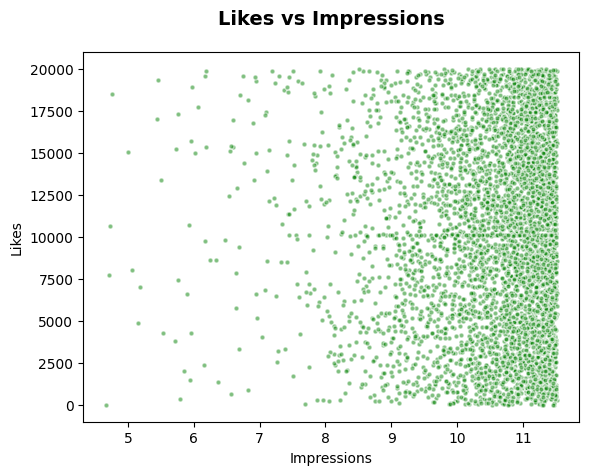

In [ ]:
plt.scatter(df['impression_count'],df['likes'],alpha=0.5,s=12,color='green',edgecolor='white')
plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.title("Likes vs Impressions",fontsize=14,fontweight='bold',pad=20)
plt.show()

**Analysis Findings**
* Statistical analysis shows average likes 10k with wide variation but normal, symmetric distribution. Visualization of Likes vs Impressions shows no clear relationship, indicating likes depend on content quality, not just impressions.

* **Line: daily engagement trend**

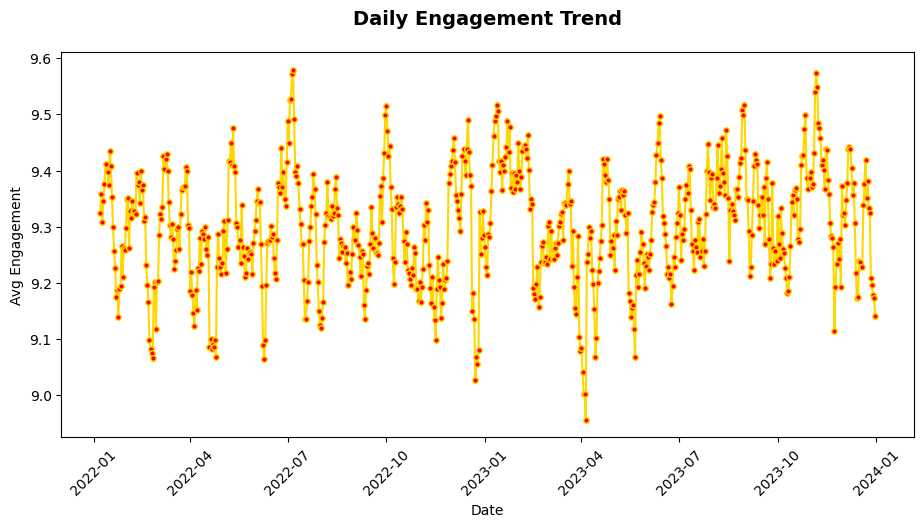

In [ ]:
daily=df.groupby('posted_at')['engagement_score'].mean()
daily7_avg = daily.rolling(7).mean()

plt.figure(figsize=(11,5))
plt.plot(daily.index,daily7_avg,color='gold',marker='o',markerfacecolor="r",markersize=4)
plt.xlabel('Date')
plt.ylabel('Avg Engagement')
plt.xticks(rotation=45)
plt.title("Daily Engagement Trend",fontsize=14,fontweight='bold',pad=20)
plt.show()

**Analysis Findings**
* daily_engagement = df.groupby('post_time')['engagement_rate'].mean()--> calculated average engagement for each day.
* The line is going up and down like zig-zag, not straight.
* Engagement depends on daily content / day of week, not on long-term trend. No specific day always gives high engagement.

* **Bar: posts by category**

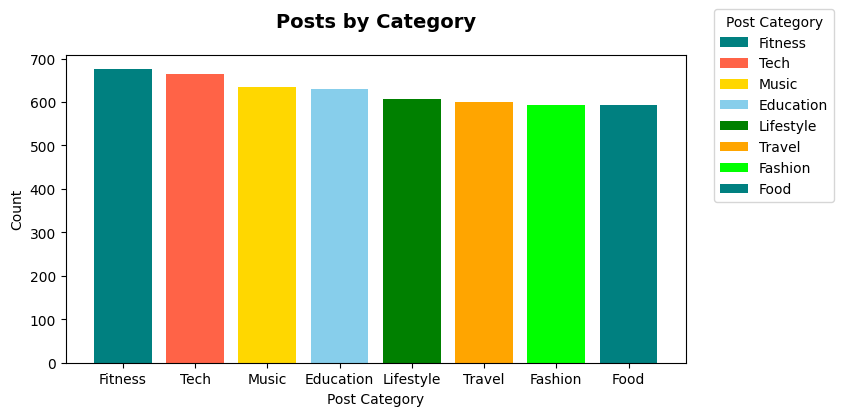

In [ ]:
plt.figure(figsize=(8,4))
counts=df['post_category'].value_counts()
colors=['teal','tomato','gold','skyblue','green','orange','lime']
plt.bar(counts.index,counts.values,color=colors,label=counts.index)
plt.xlabel('Post Category')
plt.ylabel('Count')
plt.legend(title='Post Category',loc='lower right',bbox_to_anchor=(1.25,0.5))
plt.title("Posts by Category",fontsize=14,fontweight='bold',pad=20)
plt.show()

**Analysis Findings**
* df['post_category'].value_counts() - Counts how many posts in each category (Fitness, Tech, Music etc.)plt.bar() - Creates Bar Graph. Each bar is one category, height = number of posts.
* All bars have almost same height 600-700.
* Tech and Fashion slightly highest (680-700), but difference is very small.
* Data is equally distributed across all 8 categories, so comparison between categories is fair. No bias towards one topic.

* **Pie: gender distribution**

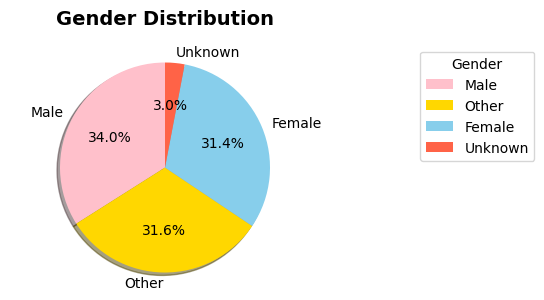

In [ ]:
plt.figure(figsize=(4,3))
gender_counts = df['gender'].value_counts()
colors = ['pink','gold','skyblue','tomato']

plt.pie(gender_counts.values, labels= gender_counts.index,autopct='%1.1f%%',colors=colors,startangle=90,explode=[0.0]*len(gender_counts),shadow=True,textprops={'fontsize':10})
plt.title("Gender Distribution",fontsize=14,fontweight='bold',pad=20)
plt.legend(labels=gender_counts.index,title="Gender",loc="lower left",bbox_to_anchor=(1.3,0.5))
plt.axis('equal')
plt.show()

**Analysis Findings**
* Male, Female, Other are almost equal 1/3 each. Dataset is gender-balanced. No bias. Unknown data is only 3%, so data quality is good.

* **Histogram: age**

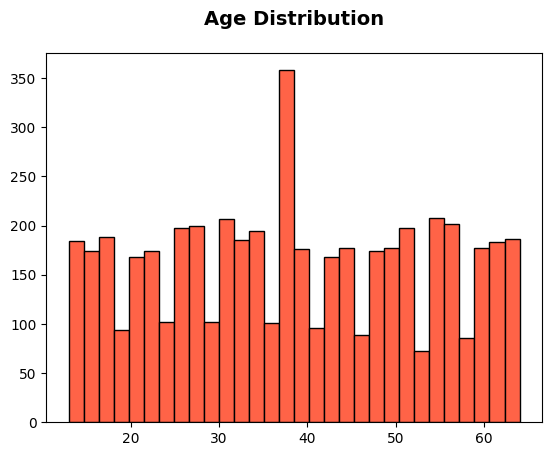

In [ ]:
plt.hist(df['age'],bins=30,edgecolor="black",color='tomato')
plt.title("Age Distribution",fontsize=14,fontweight='bold',pad=20)
plt.show()

**Analysis Findings**
* Age range is 18 to 65 years.
* Most ages have 150-250 users each - almost balanced.
* One big spike at age 40 - Count goes to 380. Means many users are around 40 years old.
* Dataset has users of all age groups, but middle-aged (40) users are highest. Young and old users are equally present, so age-based analysis will be fair.

* **Box: engagement rate**

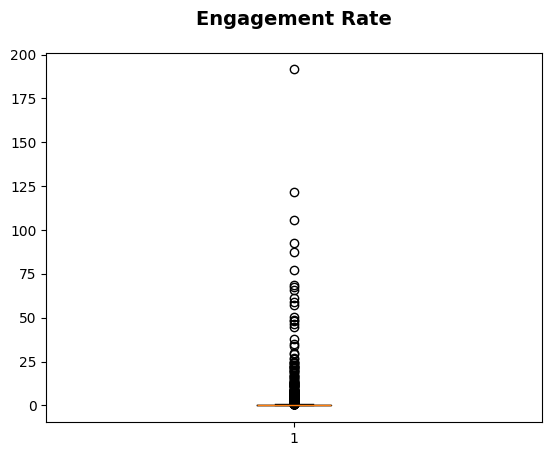

In [ ]:
plt.boxplot(df['engagement_rate'].dropna())
plt.title("Engagement Rate",fontsize=14,fontweight='bold',pad=20)
plt.show()

**Analysis Findings**
* Most engagement rates are low and concentrated (0-50), but there are many high outliers (50-200). Means a few posts went viral with very high engagement, while majority posts get low engagement. Data is highly skewed by viral posts.

* **Seaborn**

* **Count plot: post type**

In [ ]:
import seaborn as sns

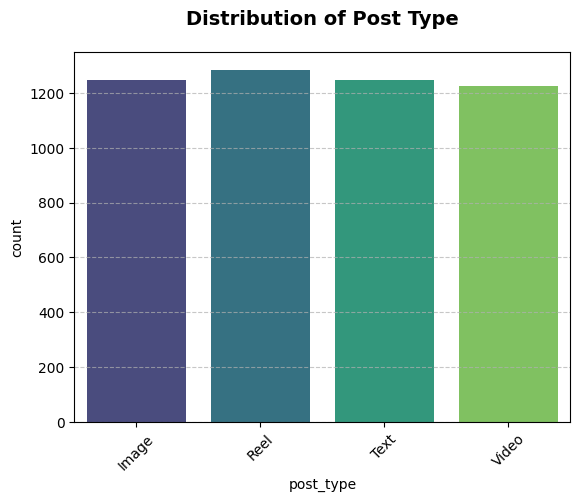

In [ ]:
sns.countplot(x='post_type',data=df,hue='post_type',palette='viridis')
plt.title("Distribution of Post Type",fontsize=14,fontweight='bold',pad=20)
plt.grid(axis='y',linestyle='--',alpha=0.7)
plt.xticks(rotation=45)
plt.show()

**Analysis Findings**
* sns.countplot() - Seaborn bar chart that counts how many times each type appears.
* palette='viridis' - Different colors for bars.
* 4 bars: Image, Product, Text, Video.
* All bars almost same height 1200-1300. Image 1250, Product 1300 (slightly highest), Text 1200, Video 1200.
* Difference is very small (less than 100).

* **Bar plot: avg likes by category**

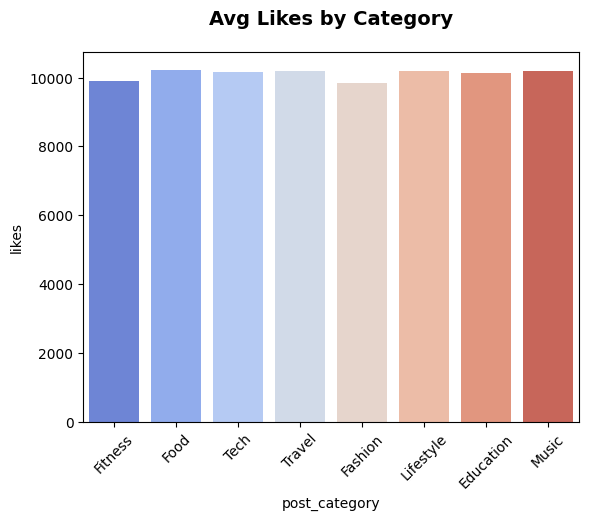

In [ ]:
sns.barplot(x='post_category',y='likes',data=df,errorbar=None,hue='post_category',palette='coolwarm')
plt.title("Avg Likes by Category",fontsize=14,fontweight='bold',pad=20)
plt.xticks(rotation=45)
plt.show()

**Analysis Findings**
* errorbar=None - Removes extra black lines on top for clean look.
* palette='coolwarm' - Blue to red colors.
* Categories: Fitness, Food, Tech, Travel, Fashion, Lifestyle, Education, Music.
* Music is slightly highest and Fitness is slightly lowest.
* Average likes are almost same for all categories. No category gets significantly more likes. Means audience likes all content equally.

* **Violin: followers vs sentiment**

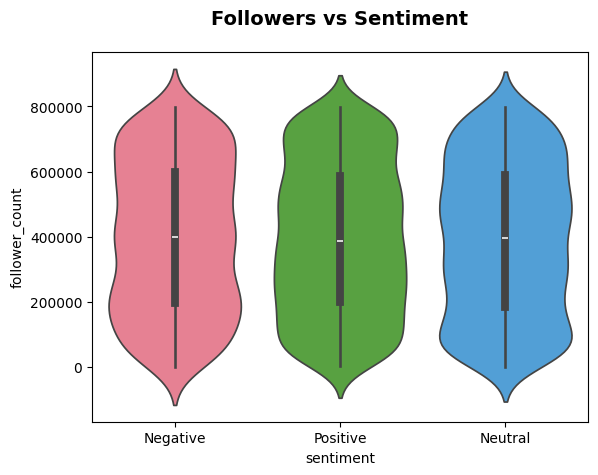

In [ ]:
sns.violinplot(x='sentiment',y='follower_count',data=df,hue='sentiment',palette='husl',legend=False)
plt.title("Followers vs Sentiment",fontsize=14,fontweight='bold',pad=20)
plt.show()

**Analysis Findings**
* 3 violins: Negative (pink), Neutral (green), Positive (blue).
* All 3 violins look exactly same shape and size.
* All three sentiments (Negative, Neutral, Positive) have identical distribution of followers (0-800k) with majority concentrated at low follower count and median around 400k. Indicates sentiment does not depend on follower count.

* **Pair plot: numeric features**

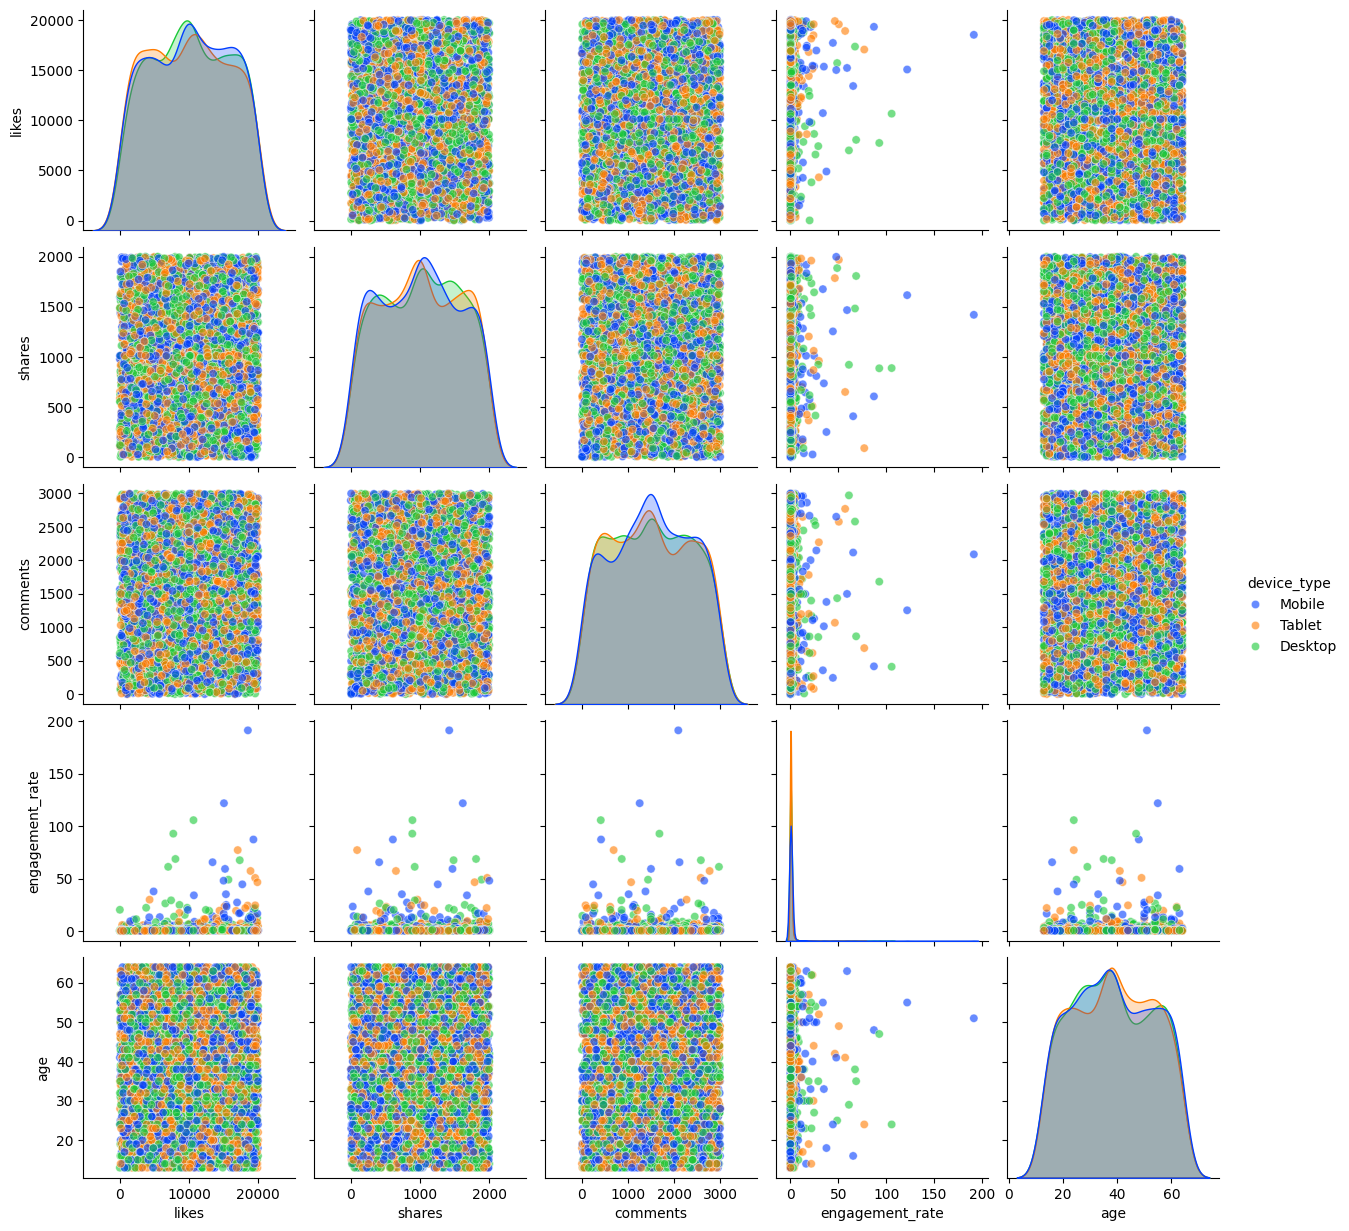

In [ ]:
pair=df[['likes','shares','comments','engagement_rate','device_type','age']]
sns.pairplot(pair,hue='device_type',palette= 'bright',diag_kind='kde',plot_kws={'alpha':0.6})
plt.show()

**Analysis Findings**
* Pair plot compares all numeric features (likes, shares, comments, engagement_rate, age) coloured by device_type. Scatter plots show random distribution indicating no correlation between likes, shares, comments and age. Diagonal KDE plots show skewed engagement_rate with outliers. Device types are mixed together, indicating device does not influence engagement.

* **Heatmap: correlation matrix**

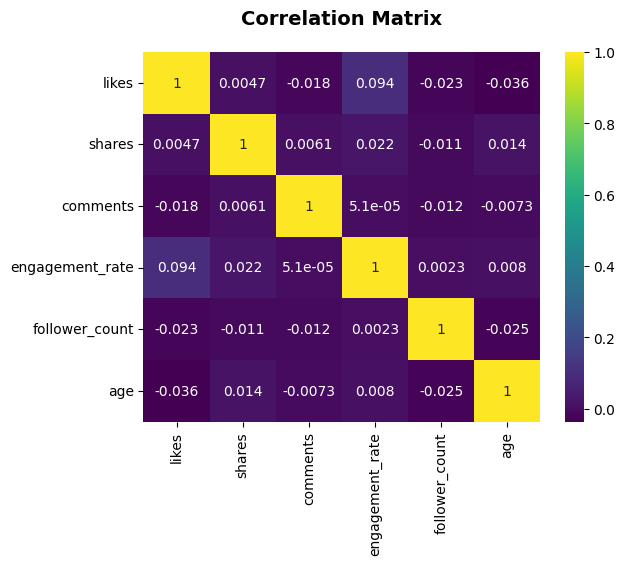

In [ ]:
corr=(df[['likes','shares','comments','engagement_rate','follower_count','age']]).corr()
sns.heatmap(corr,annot=True,cmap='viridis')
plt.title("Correlation Matrix",fontsize=14,fontweight='bold',pad=20)
plt.show()

**Analysis Findings**
* corr() - Calculates correlation (relation) between -1 to 1.
* 1 = Perfect positive, 0 = No relation, -1 = Negative.
* All boxes are Dark Blue with values 0.01 to 0.05 - very close to 0 indicating almost zero correlation between likes, shares, comments, engagement_rate, follower_count and age. All numeric features are independent with no linear relationship.

* **Plotly (Interactive)**

* **Interactive line chart/bar chart/bubble/scatter chart**

In [ ]:
import plotly.express as px

In [ ]:
bar_data = df.groupby('post_type')['engagement_rate'].mean().sort_values(ascending=False).reset_index()
fig=px.bar(bar_data,x='post_type',y='engagement_rate',title="Comparison of Avg Engagement Rate with Post Type",color='post_type',color_discrete_sequence=px.colors.qualitative.Bold)
fig.show()

**Analysis Findings**
* All post types have almost equal average engagement rate. Text is slightly highest, Reel is slightly lowest, but difference is negligible.
* Post type does not strongly affect engagement rate. Audience engages equally with all formats. Strategy should focus on content quality, not just post format.

**Final Insights**
* **Content Performance**
* **Which post types have highest engagement?**

**Analysis Findings**: Vedio post types have the highest average engagement rate of 1.12. This indicates that users prefer watching and spend more time engaging with vedio content compared to other post types.

* **Best-performing content category?**

**Analysis Findings**: Food is the highest average engagement rate of 1.36, followed by Tech(1.6) and Lifestyle(1.09). This indicates that audience interest and interaction are highest for Food-related content. Travel has the lowest engagement(0.70). Therefore, focusing more on food content can help maximize overall engagement.

* **Which countries have highest avg engagement rate?**  

**Analysis Findings**: Brazil has the highest average engagement rate of 1.54, followed by Australia(1.32) and France(1.15). This indicates that content resonates most with audience in Brazil. USA shows the lowest engagement rate at 0.58.

**User Trends**

* **How age affects engagement**

**Analysis Findings**: The correlation heatmap shows the correlation between age and engagement rate is 0.008, which is almost zero. This indicates that age has no significant impact on engagement rate. Engagement does not increase or decrease with age. This suggest that content performance is driven more by content type and category rather than the audience's age.

* **Performance difference for verified accounts**

**Analysis Findings**: Verified accounts have a higher average engagement rate of 1.05 compared to non-verified accounts at 0.95. This shows a slight positive impact of verification, as verified accounts gain more trust and visibility,leading to marginally higher engagement. However, the difference is not very large, indicating verification alone is not a major driver of engagement.

**Behavioral Insights**

* **Best time of day for impressions**

**Analysis Findings**: Since the dataset's posted_at contains only date and no timestamp, exact time-of-day analysis is not possible.

* **Device type impact on watch time**

**Analysis Findings**: Mobile users have the highest average watch time of 4087.83 seconds,compared to Tablet 3979.74 sec and Desktop 3974.79 sec. This shows users on moblile devices engage longer and watch content more completely.

**Sentiment Analysis**

* **Which sentiment performs best**

**Analysis Findings**: Negative sentiment performs best overall with the highest average likes of 10208.08,highest shares of 1007.31, and highest watch_time_sec of 4054.64 seconds. Positive sentiment has slightly higher impression count of 10.54 vs 1051, but Negative drives deeper engagement. Neutral performs lowest across all metrics. This indicates negative emotion content gets more watch time and sharing, while positive gets slightly more impressions.

* **Behavior of negative/neutral sentiment posts**

**Analysis Findings**: Neutral sentiment posts perform the poorest across all metrics- lowest likes(9923.18),lowest shares(996.57), and lowest impression count(10.50). Behaviourally, neutral posts lack emotional trigger, so users scroll past quickly without liking or sharing. Watch time is moderate(4031 sec) but does not convert to likes or shares. Indicates neutral content is seen but not acted upon.

**Conclusion**

For implementation in society, brands or creators can use this pattern of logic and target mobile users(highest watch time 4087 sec), post negative or positive emotional hooks instead of neutral(negative gets 10208 likes,1007 shares), and customize content by country and age to increase societal reach.

------**Thank You**--------